# Run OCEANLYZ on the cleaned pressure data

Runs [OCEANLYZ](https://github.com/akarimp/Oceanlyz) burst-by-burst on the
`oceanlyz.csv` / `clean.csv` files that `pressure_calibrate_and_prepare.ipynb`
wrote into each site's output folder, and turns them into wave statistics:
Hm0 (significant wave height), Hmax (largest individual wave per burst),
three period estimates (Tp, Tm01, Tm02), wave energy density, spectra, and
water depth, across the whole deployment. It also reconstructs the
individual waves themselves (via zero down-crossing on the corrected
sea-surface elevation) as a wave-by-wave height time series per sensor, and
splits the spectrum into **infragravity / swell / sea (wind-wave)** bands
so you can see how the energy balance between them shifts from site to
site - e.g. short gravity waves being damped by a mangrove fringe while
infragravity energy passes through largely unaffected.

Run `pressure_calibrate_and_prepare.ipynb` first for each site you want to
analyse - this notebook reads its output folders directly and doesn't
duplicate any of that cleaning/calibration work.

With 2+ sites configured, section 7 adds cross-site comparison plots (Hm0,
Hmax, period, energy, mean spectra, infragravity fraction, and each site's
wave height/energy relative to a reference site) saved into their own
`comparison_<site1>_<site2>_...` folder.

**Notes:**
- The pip-installed OCEANLYZ 2.0 has a small bug where it crashes if `fs`
  is a Python float (`n_sample = fs*burst_duration` ends up non-integer).
  This notebook works around it by keeping `fs` as an `int` - harmless, and
  still correct as long as your sampling rate is a whole number of Hz.
  Also make sure `fs` is the sensor's *actual* sampling rate for each site
  - if it's wrong, every frequency (and therefore every period) in the
  output will be scaled by the ratio of the wrong-to-right value.
- OCEANLYZ's `fmin` setting zeroes out the spectrum below that frequency
  entirely (not just excludes it from `Hm0`/`Tp` - the raw `Syy` values
  are actually zero there too). That means **if `fmin` is set above the
  infragravity band, this notebook's infragravity columns will be zero for
  that site** - see section 3.

## 1. Connect to Google Drive

Gives this notebook access to the files in your Drive, including the site output folders from the calibration notebook.

In [47]:
from google.colab import drive
drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Set the working directory

This should be the same folder you ran `pressure_calibrate_and_prepare.ipynb`
from - the one containing each site's output folder (e.g. `unive1/`). Type
its path, or press Enter to use the notebook's current directory.

In [48]:
import os

PROJECT_DIR = input(f"Working directory [{os.getcwd()}]: ").strip() or os.getcwd()
os.chdir(PROJECT_DIR)
print("Working directory:", os.getcwd())
print("Contents:", sorted(os.listdir(".")))


Working directory [/content/drive/Othercomputers/My Mac/Documents/GitHub/seastrong-field-tools/Wave_data_processing]: 
Working directory: /content/drive/Othercomputers/My Mac/Documents/GitHub/seastrong-field-tools/Wave_data_processing
Contents: ['Data', 'Offshore_200m', 'Onshore_30m', 'pressure_calibrate_and_prepare.ipynb', 'processing_summary.csv', 'run_oceanlyz.ipynb', 'scripts']


In [49]:
# In Google Colab, this installs OCEANLYZ (and seaborn, for the plots) into the runtime.
!pip install oceanlyz seaborn --quiet


In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import oceanlyz

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

G = 9.81  # gravitational acceleration (m/s^2), for wave energy density


## 3. Configuration

One entry per site folder to analyse (each must already contain
`oceanlyz.csv` and `clean.csv` from the calibration notebook).

- `name` - the site's output folder name (e.g. `"unive1"`), also used to
  label plots/results. Must match the folder exactly.
- `fs` - sampling frequency (Hz), as an `int`. Must be the sensor's true
  sampling rate - get it wrong and every frequency/period this notebook
  reports for that site will be wrong too.
- `heightfrombed` - how far the sensor sits above the seabed (m); `0.0` if
  it was resting directly on the bed. Feeds directly into OCEANLYZ's
  pressure-attenuation correction.
- `rho` - water density (kg/m³) at that site: ~1025 seawater, ~1000
  freshwater.
- `fmin` - the lowest frequency kept in the whole analysis (Hz). **This
  must be set below `IG_MAX_HZ` (below) for a site's infragravity columns
  to be anything other than zero** - OCEANLYZ discards everything below
  `fmin` before it ever reaches this notebook. `0.01` Hz is a reasonable
  default if you want infragravity energy; the old default of `0.05` Hz
  deliberately excludes it.
- `fminpcorr` - the lowest frequency OCEANLYZ's automatic pressure-
  correction cutoff (`fmaxpcorr`) is allowed to land on. Unrelated to
  `fmin` above - this only affects the high end of the correction, not
  what's kept at the low end.
- `nfft` (optional, default `1024`) - number of FFT points per burst.
  Larger values give finer frequency resolution (more bins inside the
  narrow infragravity band), at the cost of noisier individual bins - it
  should be a power of 2, and increasing it only helps up to roughly
  `fs * burst_duration_s` (beyond that you're just interpolating, not
  adding real resolution). The default 512 used by earlier versions of
  this notebook gave only ~5 frequency bins across the whole infragravity
  band; `1024` roughly doubles that.

**Frequency bands** (edit these if your region's wave climate calls for
different splits - the values below are common textbook defaults, not a
universal standard):

- `IG_MAX_HZ = 0.04` (period > 25 s) - the upper edge of the infragravity
  band. Infragravity waves are generated by groups of shorter waves and,
  unlike wind sea and swell, are barely attenuated by bottom friction or
  vegetation - so they often become the *dominant* signal in a sheltered
  setting (a mangrove fringe, a reef lagoon) even though they're a minor
  part of the energy offshore. This is the effect worth checking for if
  you're comparing an exposed site to a vegetated/sheltered one.
- `SWELL_MAX_HZ = 0.1` (period 10-25 s is swell, < 10 s is wind sea /
  "sea"). Everything between `IG_MAX_HZ` and `SWELL_MAX_HZ` is counted as
  swell; everything above `SWELL_MAX_HZ` (up to `fs/2`) as wind sea.

`BURST_DURATION_S` - length of each analysis burst, in seconds. 1800
(30 min) is a common default.

`REFERENCE_SITE` - which site section 7's "relative to reference" plot is
computed against. Only used when 2+ sites are configured.

`SITE_COLORS` assigns each site a fixed colour, reused across every plot in
this notebook.

In [51]:
INPUT_DIR = "."  # folder containing each site's output subfolder

BURST_DURATION_S = 1800  # 30 minutes

IG_MAX_HZ = 0.04      # upper edge of the infragravity band (Hz)
SWELL_MAX_HZ = 0.1    # upper edge of the swell band / start of wind sea (Hz)

SITES = [
    {
        "name": "Offshore_200m",
        "fs": 4,                 # int on purpose - see note above
        "heightfrombed": 0.0,
        "rho": 1025,
        "fmin": 0.01,             # below IG_MAX_HZ, so infragravity is kept - see note above
        "fminpcorr": 0.05,
        "nfft": 1024,
    },
    # Add another site:
    {
         "name": "Onshore_30m",
         "fs": 4,
         "heightfrombed": 0.0,
         "rho": 1025,
         "fmin": 0.01,
         "fminpcorr": 0.05,
         "nfft": 1024,
    },
]

REFERENCE_SITE = SITES[0]["name"]
SITE_COLORS = dict(zip(
    [s["name"] for s in SITES],
    sns.color_palette("colorblind", n_colors=len(SITES)),
))
BAND_COLORS = dict(zip(["infragravity", "swell", "sea"], sns.color_palette("Set2", 3)))

# All cross-site comparison outputs (section 7) go in one folder, named
# after every site configured above, created once here so every later cell
# reuses the same path.
COMPARISON_DIR = "comparison_" + "_".join(s["name"] for s in SITES)
if len(SITES) > 1:
    os.makedirs(COMPARISON_DIR, exist_ok=True)
    print("Comparison output folder:", COMPARISON_DIR)

for s in SITES:
    if s["fmin"] >= IG_MAX_HZ:
        print(f"Note: {s['name']}'s fmin ({s['fmin']} Hz) is >= IG_MAX_HZ ({IG_MAX_HZ} Hz) - "
              f"infragravity columns for this site will be zero. Lower fmin if you want that band.")


Comparison output folder: comparison_Offshore_200m_Onshore_30m


## 4. Load data, split into whole bursts, and run OCEANLYZ

For each burst, this notebook computes more than OCEANLYZ's own `Hm0`/`Tp`/
`fp` output, all from the spectrum (`f`, `Syy`) OCEANLYZ already returns:

- **Tm01 = m0 / m1** and **Tm02 = sqrt(m0 / m2)** - two more period
  estimates, from the spectral moments `m_n = integral(f^n * Syy df)`.
  Both are usually a bit shorter than the peak period `Tp` and less
  sensitive to a noisy spectral peak.
- **wave energy density, E = rho * g * m0** (J/m²) - proportional to
  `Hm0²`, computed here over the *whole* retained spectrum (i.e. whatever
  `fmin`-`fmax` keeps).
- **infragravity / swell / sea energy and Hm0-equivalent** - the same
  `m0`-based calculation as above, but restricted to each frequency band
  in turn (`band_energy()` below). `energy_ig_Jm2 + energy_swell_Jm2 +
  energy_sea_Jm2` should add up to close to the total `wave_energy_Jm2`
  (small differences come from frequencies right at fmin/fmax getting
  split unevenly across bins). `ig_fraction_pct` is the infragravity
  share of the total energy - the number to watch if you're checking
  whether a sheltered site is becoming infragravity-dominated.
- **Hmax** - the height of the single largest individual wave in each
  burst, and a full **wave-by-wave height time series**
  (`{site}_wave_heights.csv`, plotted in section 6) - both come from
  applying the classic zero down-crossing method to OCEANLYZ's
  reconstructed sea-surface elevation (`Eta`).

In [52]:
def spectral_moments(f, Syy):
    """m0/m1/m2 per burst from OCEANLYZ's (n_burst, n_freq) f and Syy arrays."""
    m0 = np.trapz(Syy, f, axis=1)
    m1 = np.trapz(f * Syy, f, axis=1)
    m2 = np.trapz((f ** 2) * Syy, f, axis=1)
    return m0, m1, m2


def band_energy(f, Syy, bands):
    """
    m0 (spectral variance) per burst, restricted to each named frequency
    band. bands: dict of name -> (f_low, f_high), Hz, half-open [low, high).
    Uses just m0 (not m1/m2) since these bands can be narrow enough that
    higher moments get noisy; m0 alone is enough for a band's Hm0 and
    energy. Returns dict of name -> array (n_burst,), NaN for a burst/band
    with fewer than 2 frequency bins inside it (can't integrate).
    """
    freqs = f[0]  # same frequency axis for every burst
    out = {}
    for name, (f_low, f_high) in bands.items():
        mask = (freqs >= f_low) & (freqs < f_high)
        if mask.sum() >= 2:
            out[name] = np.trapz(Syy[:, mask], freqs[mask], axis=1)
        else:
            out[name] = np.full(Syy.shape[0], np.nan)
    return out


def zero_crossing_wave_heights(eta, fs):
    """
    Individual wave heights from a reconstructed sea-surface elevation
    time series (one burst), via the zero down-crossing method: each
    stretch of `eta` between two consecutive downward zero-crossings is one
    wave, and its height is that stretch's crest-to-trough range.

    Returns (heights_m, crest_sample_idx) - crest_sample_idx is where each
    wave's peak occurs, in samples from the start of `eta`, used to give
    each wave a real timestamp.
    """
    signs = np.sign(eta)
    signs[signs == 0] = 1
    downcross = np.where((signs[:-1] > 0) & (signs[1:] <= 0))[0]
    heights, crest_idx = [], []
    for i in range(len(downcross) - 1):
        seg = eta[downcross[i]:downcross[i + 1] + 1]
        heights.append(seg.max() - seg.min())
        crest_idx.append(downcross[i] + int(np.argmax(seg)))
    return np.array(heights), np.array(crest_idx)


def load_and_trim(site, input_dir=INPUT_DIR, burst_duration_s=BURST_DURATION_S):
    """
    Load the pressure vector and matching timestamps from the site's output
    folder, and trim both to an exact whole number of bursts (OCEANLYZ
    requires len(data) == n_burst * burst_duration * fs exactly).
    """
    site_dir = os.path.join(input_dir, site["name"])
    oceanlyz_path = os.path.join(site_dir, "oceanlyz.csv")
    clean_path = os.path.join(site_dir, "clean.csv")
    if not (os.path.exists(oceanlyz_path) and os.path.exists(clean_path)):
        raise FileNotFoundError(
            f"Couldn't find {oceanlyz_path} / {clean_path} - run "
            f"pressure_calibrate_and_prepare.ipynb for '{site['name']}' first."
        )

    data = np.genfromtxt(oceanlyz_path)
    timestamps = pd.to_datetime(pd.read_csv(clean_path, usecols=["datetime"])["datetime"])

    samples_per_burst = site["fs"] * burst_duration_s
    n_burst = len(data) // samples_per_burst
    n_used = n_burst * samples_per_burst

    data_trim = data[:n_used]
    burst_start_times = timestamps.iloc[0:n_used:samples_per_burst].reset_index(drop=True)

    return data_trim, n_burst, burst_start_times, site_dir


def run_oceanlyz_site(site, burst_duration_s=BURST_DURATION_S, input_dir=INPUT_DIR):
    data_trim, n_burst, burst_start_times, site_dir = load_and_trim(
        site, input_dir=input_dir, burst_duration_s=burst_duration_s
    )

    ocn = oceanlyz.oceanlyz()
    ocn.data = data_trim.copy()
    ocn.InputType = "pressure"
    ocn.OutputType = "wave+waterlevel"
    ocn.AnalysisMethod = "spectral"
    ocn.n_burst = n_burst
    ocn.burst_duration = burst_duration_s
    ocn.fs = site["fs"]
    ocn.fmin = site["fmin"]
    ocn.fmax = site["fs"] / 2
    ocn.fmaxpcorrCalcMethod = "auto"
    ocn.Kpafterfmaxpcorr = "constant"
    ocn.fminpcorr = site["fminpcorr"]
    ocn.fmaxpcorr = site["fs"] / 2
    ocn.heightfrombed = site["heightfrombed"]
    ocn.Rho = site["rho"]
    ocn.nfft = site.get("nfft", 1024)
    ocn.dispout = "no"

    ocn.runoceanlyz()

    mean_depth_m = np.asarray(ocn.wave["Burst_Data"]).mean(axis=1)
    f = np.asarray(ocn.wave["f"])
    Syy = np.asarray(ocn.wave["Syy"])
    Eta = np.asarray(ocn.wave["Eta"])
    m0, m1, m2 = spectral_moments(f, Syy)

    bands = {
        "infragravity": (0.0, IG_MAX_HZ),
        "swell": (IG_MAX_HZ, SWELL_MAX_HZ),
        "sea": (SWELL_MAX_HZ, site["fs"] / 2 + 1e-9),
    }
    band_m0 = band_energy(f, Syy, bands)
    rho = site["rho"]

    Hmax_m = np.full(n_burst, np.nan)
    wave_rows = []
    for b in range(n_burst):
        heights, crest_idx = zero_crossing_wave_heights(Eta[b], site["fs"])
        if len(heights):
            Hmax_m[b] = heights.max()
            crest_times = burst_start_times.iloc[b] + pd.to_timedelta(crest_idx / site["fs"], unit="s")
            wave_rows.append(pd.DataFrame({"time": crest_times, "H_m": heights}))
    waves = pd.concat(wave_rows, ignore_index=True) if wave_rows else pd.DataFrame(columns=["time", "H_m"])
    waves_path = os.path.join(site_dir, "wave_heights.csv")
    waves.to_csv(waves_path, index=False)

    energy_total = rho * G * m0
    energy_ig = rho * G * band_m0["infragravity"]

    results = pd.DataFrame({
        "burst_start": burst_start_times,
        "mean_depth_m": mean_depth_m,
        "Hm0_m": ocn.wave["Hm0"],
        "Hmax_m": Hmax_m,
        "Tp_s": ocn.wave["Tp"],
        "Tm01_s": m0 / m1,
        "Tm02_s": np.sqrt(m0 / m2),
        "fp_Hz": ocn.wave["fp"],
        "wave_energy_Jm2": energy_total,
        "Hm0_ig_m": 4 * np.sqrt(band_m0["infragravity"]),
        "Hm0_swell_m": 4 * np.sqrt(band_m0["swell"]),
        "Hm0_sea_m": 4 * np.sqrt(band_m0["sea"]),
        "energy_ig_Jm2": energy_ig,
        "energy_swell_Jm2": rho * G * band_m0["swell"],
        "energy_sea_Jm2": rho * G * band_m0["sea"],
        "ig_fraction_pct": 100 * energy_ig / energy_total,
    })

    out_path = os.path.join(site_dir, "oceanlyz_results.csv")
    results.to_csv(out_path, index=False)

    mean_spectrum = {"f": f.mean(axis=0), "Syy_mean": Syy.mean(axis=0)}

    return ocn, results, mean_spectrum, waves, out_path, site_dir


## 5. Run for every site

For each site in `SITES`, this loads its data, runs OCEANLYZ, and prints a
quick summary table (mean/std/min/max across all bursts) so you can sanity
check the results before looking at any plots - e.g. does the mean depth
match what you expect, is `Hmax` bigger than `Hm0` (it always should be),
and is `ig_fraction_pct` actually nonzero (if it's all zero/NaN, check that
`fmin` for that site is below `IG_MAX_HZ`, per the note in section 3).

In [53]:
ocn_objects = {}
all_results = {}
spectra = {}
wave_heights = {}
site_dirs = {}

for site in SITES:
    ocn, results, mean_spectrum, waves, out_path, site_dir = run_oceanlyz_site(site)
    ocn_objects[site["name"]] = ocn
    all_results[site["name"]] = results
    spectra[site["name"]] = mean_spectrum
    wave_heights[site["name"]] = waves
    site_dirs[site["name"]] = site_dir

    print(f"\n=== {site['name'].upper()} ===")
    print(f"{len(results)} bursts of {BURST_DURATION_S/60:.0f} min, {len(waves)} individual waves reconstructed")
    print(f"Wrote: {out_path}")
    print(f"Wrote: {os.path.join(site_dir, 'wave_heights.csv')}")
    print(results.describe().loc[
        ["mean", "std", "min", "max"],
        ["mean_depth_m", "Hm0_m", "Hmax_m", "Tp_s", "Tm01_s", "Tm02_s", "wave_energy_Jm2", "ig_fraction_pct"],
    ])


--------------------------------------------------
OCEANLYZ Ver 2.0
www.ArashKarimpour.com
Copyright (C) 2012 - 2026  Arash Karimpour
--------------------------------------------------
Parameters (only required ones used)
--------------------------------------------------
InputType           :  pressure
OutputType          :  wave+waterlevel
-------------------------------
AnalysisMethod      :  spectral
-------------------------------
n_burst             :  66
burst_duration      :  1800
fs                  :  4
-------------------------------
fmin                :  0.01
fmax                :  2.0
-------------------------------
fmaxpcorrCalcMethod :  auto
Kpafterfmaxpcorr    :  constant
fminpcorr           :  0.05
fmaxpcorr           :  2.0
heightfrombed       :  0.0
-------------------------------
dispout             :  no
-------------------------------
Rho                 :  1025
nfft                :  1024
-------------------------------
SeparateSeaSwell    :  no
fpminswell      

/tmp/ipykernel_4127/3234248712.py:3: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  m0 = np.trapz(Syy, f, axis=1)
/tmp/ipykernel_4127/3234248712.py:4: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  m1 = np.trapz(f * Syy, f, axis=1)
/tmp/ipykernel_4127/3234248712.py:5: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  m2 = np.trapz((f ** 2) * Syy, f, axis=1)
/tmp/ipykernel_4127/3234248712.py:23: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  out[name] = np.trapz(Syy[:, mask], freqs[mask], axis=1)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and sc


=== OFFSHORE_200M ===
66 bursts of 30 min, 23926 individual waves reconstructed
Wrote: ./Offshore_200m/oceanlyz_results.csv
Wrote: ./Offshore_200m/wave_heights.csv
      mean_depth_m     Hm0_m    Hmax_m      Tp_s    Tm01_s    Tm02_s  \
mean      3.972118  0.608328  0.969690  7.093757  5.068255  3.760567   
std       0.029243  0.173317  0.292400  0.861175  0.518614  0.439262   
min       3.914768  0.289922  0.442211  5.333333  4.140087  3.123026   
max       4.034821  0.896251  1.557075  8.258065  6.230122  5.227030   

      wave_energy_Jm2  ig_fraction_pct  
mean       251.145975         1.689764  
std        130.725207         0.712019  
min         52.824324         0.542136  
max        504.794386         2.886467  


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


--------------------------------------------------
OCEANLYZ Ver 2.0
www.ArashKarimpour.com
Copyright (C) 2012 - 2026  Arash Karimpour
--------------------------------------------------
Parameters (only required ones used)
--------------------------------------------------
InputType           :  pressure
OutputType          :  wave+waterlevel
-------------------------------
AnalysisMethod      :  spectral
-------------------------------
n_burst             :  66
burst_duration      :  1800
fs                  :  4
-------------------------------
fmin                :  0.01
fmax                :  2.0
-------------------------------
fmaxpcorrCalcMethod :  auto
Kpafterfmaxpcorr    :  constant
fminpcorr           :  0.05
fmaxpcorr           :  2.0
heightfrombed       :  0.0
-------------------------------
dispout             :  no
-------------------------------
Rho                 :  1025
nfft                :  1024
-------------------------------
SeparateSeaSwell    :  no
fpminswell      

/tmp/ipykernel_4127/3234248712.py:3: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  m0 = np.trapz(Syy, f, axis=1)
/tmp/ipykernel_4127/3234248712.py:4: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  m1 = np.trapz(f * Syy, f, axis=1)
/tmp/ipykernel_4127/3234248712.py:5: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  m2 = np.trapz((f ** 2) * Syy, f, axis=1)
/tmp/ipykernel_4127/3234248712.py:23: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  out[name] = np.trapz(Syy[:, mask], freqs[mask], axis=1)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and sc


=== ONSHORE_30M ===
66 bursts of 30 min, 23602 individual waves reconstructed
Wrote: ./Onshore_30m/oceanlyz_results.csv
Wrote: ./Onshore_30m/wave_heights.csv
      mean_depth_m     Hm0_m    Hmax_m      Tp_s    Tm01_s    Tm02_s  \
mean      2.484102  0.630446  1.021047  7.085183  4.974420  3.697951   
std       0.062892  0.184471  0.302655  0.873142  0.424242  0.406113   
min       2.368242  0.283529  0.470859  5.446809  4.103134  2.999624   
max       2.588236  0.925034  1.676515  8.258065  5.988913  4.894408   

      wave_energy_Jm2  ig_fraction_pct  
mean       270.842446         2.218177  
std        143.219045         1.037508  
min         50.520464         0.688549  
max        537.749828         4.414944  


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 6. Per-site plots

Four figures per site, saved into that site's own output folder:

- **`{name}_wave_conditions.png`** - wave height (Hm0 and Hmax), depth,
  periods, and total energy density, against time.
- **`{name}_mean_spectrum.png`** - the burst-averaged frequency spectrum,
  with the infragravity/swell/sea band edges marked.
- **`{name}_wave_heights.png`** - every individual wave reconstructed by
  the zero down-crossing method, with `Hm0` overlaid as a reference.
- **`{name}_band_energy.png`** - two panels: absolute energy density in
  each band over time (top), and each band's *share* of the total energy
  over time (bottom, 0-100%). The bottom panel is the one to watch for a
  sheltered/vegetated site becoming infragravity-dominated over the
  deployment or during particular tidal/wave conditions.

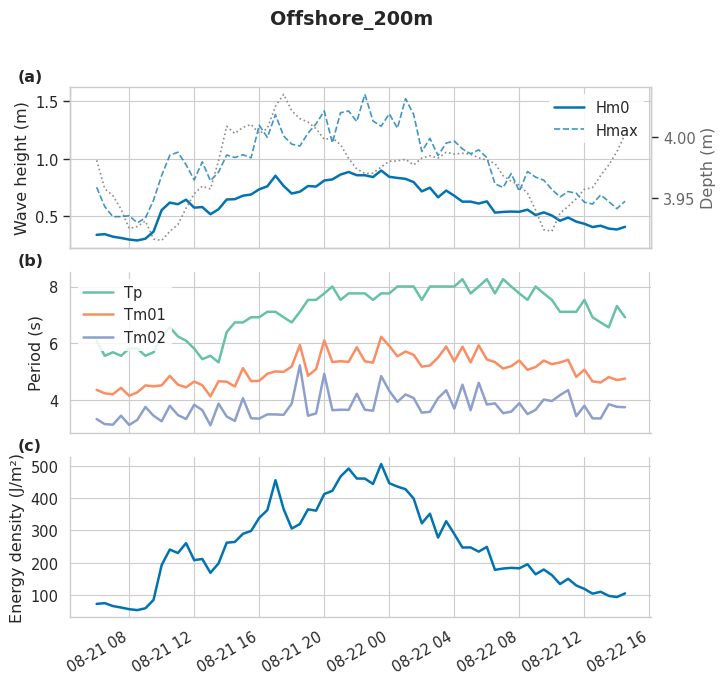

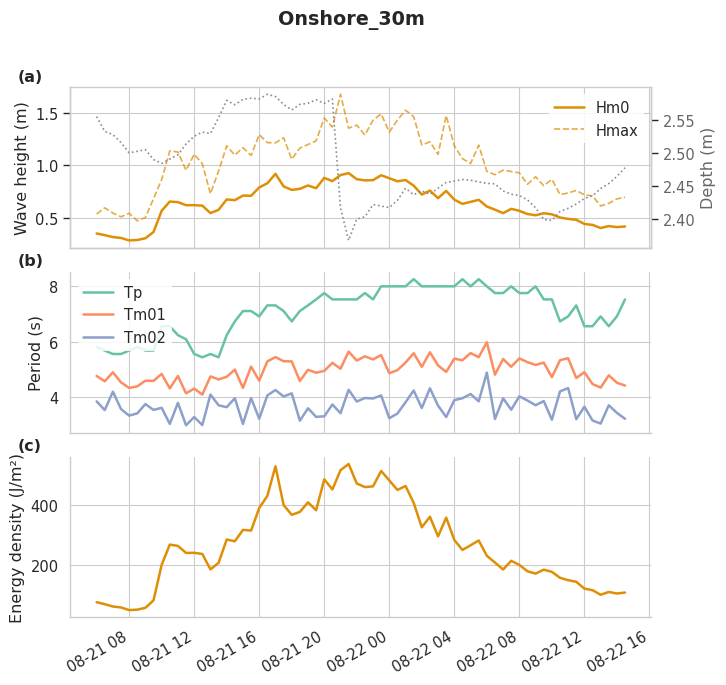

In [54]:
PERIOD_COLORS = dict(zip(["Tp", "Tm01", "Tm02"], sns.color_palette("Set2", 3)))

for site in SITES:
    name = site["name"]
    results = all_results[name]
    color = SITE_COLORS[name]

    fig, axes = plt.subplots(3, 1, figsize=(7.5, 7.8), sharex=True,
                              gridspec_kw={"hspace": 0.15})

    ax = axes[0]
    ax.plot(results["burst_start"], results["Hm0_m"], color=color, lw=1.8, label="Hm0")
    ax.plot(results["burst_start"], results["Hmax_m"], color=color, lw=1.2, ls="--", alpha=0.75, label="Hmax")
    ax.set_ylabel("Wave height (m)")
    ax.legend(loc="best", framealpha=0.85, edgecolor="none")
    ax_depth = ax.twinx()
    ax_depth.plot(results["burst_start"], results["mean_depth_m"], color="0.55", lw=1.2, ls=":")
    ax_depth.set_ylabel("Depth (m)", color="0.4")
    ax_depth.tick_params(axis="y", labelcolor="0.4")
    ax_depth.grid(False)
    ax.text(-0.09, 1.04, "(a)", transform=ax.transAxes, fontweight="bold")
    sns.despine(ax=ax, top=True, right=False)

    ax = axes[1]
    for label in ["Tp_s", "Tm01_s", "Tm02_s"]:
        short = label.split("_")[0]
        ax.plot(results["burst_start"], results[label], color=PERIOD_COLORS[short], lw=1.8, label=short)
    ax.set_ylabel("Period (s)")
    ax.legend(loc="best", framealpha=0.85, edgecolor="none")
    ax.text(-0.09, 1.04, "(b)", transform=ax.transAxes, fontweight="bold")
    sns.despine(ax=ax)

    ax = axes[2]
    ax.plot(results["burst_start"], results["wave_energy_Jm2"], color=color, lw=1.8)
    ax.set_ylabel("Energy density (J/m²)")
    ax.text(-0.09, 1.04, "(c)", transform=ax.transAxes, fontweight="bold")
    sns.despine(ax=ax)

    for a in axes[:-1]:
        a.tick_params(labelbottom=False)
    fig.autofmt_xdate()
    fig.suptitle(name, fontweight="bold")
    fig.savefig(os.path.join(site_dirs[name], f"{name}_wave_conditions.png"), dpi=200, bbox_inches="tight")
    plt.show()


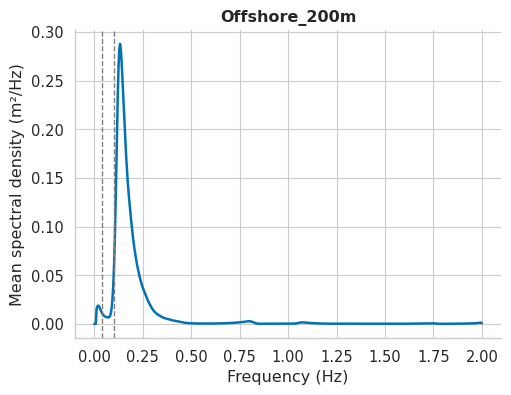

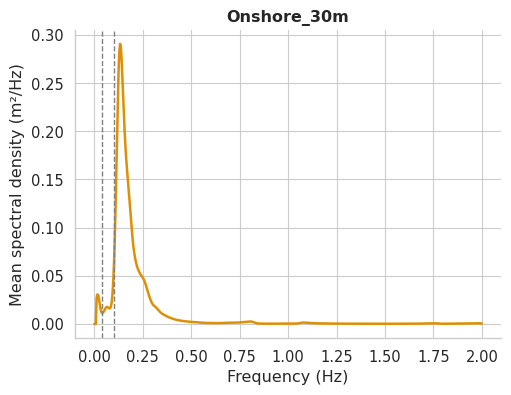

In [55]:
for site in SITES:
    name = site["name"]
    spec = spectra[name]
    color = SITE_COLORS[name]

    fig, ax = plt.subplots(figsize=(5.5, 4))
    ax.plot(spec["f"], spec["Syy_mean"], color=color, lw=1.8)
    for edge in (IG_MAX_HZ, SWELL_MAX_HZ):
        ax.axvline(edge, color="0.5", lw=1, ls="--")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Mean spectral density (m²/Hz)")
    ax.set_title(name, fontweight="bold")
    sns.despine(ax=ax)
    fig.savefig(os.path.join(site_dirs[name], f"{name}_mean_spectrum.png"), dpi=200, bbox_inches="tight")
    plt.show()


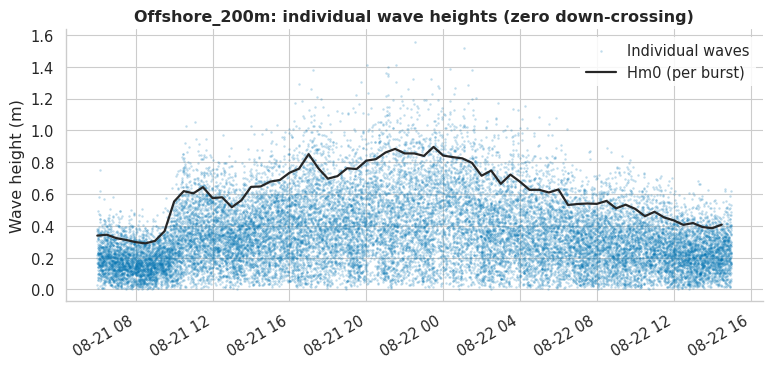

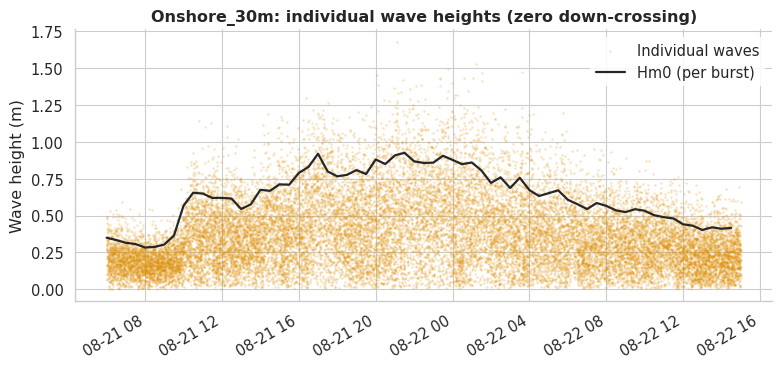

In [56]:
for site in SITES:
    name = site["name"]
    waves = wave_heights[name]
    results = all_results[name]
    color = SITE_COLORS[name]

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.scatter(waves["time"], waves["H_m"], s=3, alpha=0.25, color=color, linewidths=0, label="Individual waves")
    ax.plot(results["burst_start"], results["Hm0_m"], color="0.15", lw=1.6, label="Hm0 (per burst)")
    ax.set_ylabel("Wave height (m)")
    ax.set_title(f"{name}: individual wave heights (zero down-crossing)", fontweight="bold")
    ax.legend(loc="best", framealpha=0.85, edgecolor="none")
    sns.despine(ax=ax)
    fig.autofmt_xdate()
    fig.savefig(os.path.join(site_dirs[name], f"{name}_wave_heights.png"), dpi=200, bbox_inches="tight")
    plt.show()


/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2012: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.style_literal  = oneOf(
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2020: PyparsingDeprecationWarning: 'leaveWhitespace' deprecated - use 'leave_whitespace'
  )("sym").leaveWhitespace()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2024: PyparsingDeprecationWarning: 'oneO

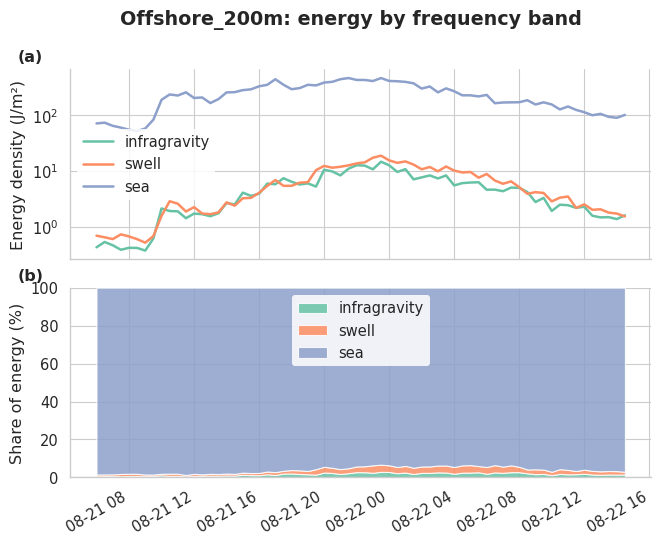

/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetim

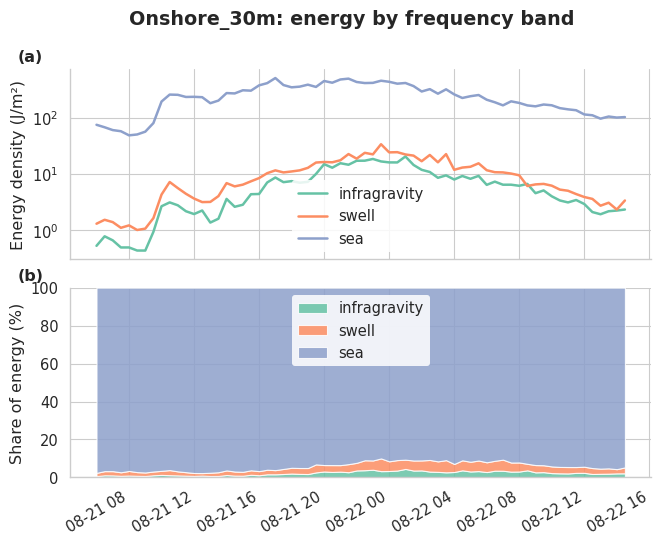

In [57]:
for site in SITES:
    name = site["name"]
    results = all_results[name]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.5, 6), sharex=True,
                                    gridspec_kw={"hspace": 0.15})

    for band, col in [("infragravity", "energy_ig_Jm2"), ("swell", "energy_swell_Jm2"), ("sea", "energy_sea_Jm2")]:
        ax1.plot(results["burst_start"], results[col], color=BAND_COLORS[band], lw=1.8, label=band)
    ax1.set_ylabel("Energy density (J/m²)")
    ax1.set_yscale("log")
    ax1.legend(loc="best", framealpha=0.85, edgecolor="none")
    ax1.text(-0.09, 1.04, "(a)", transform=ax1.transAxes, fontweight="bold")
    sns.despine(ax=ax1)

    fractions = pd.DataFrame({
        "infragravity": results["energy_ig_Jm2"],
        "swell": results["energy_swell_Jm2"],
        "sea": results["energy_sea_Jm2"],
    })
    fractions = fractions.div(fractions.sum(axis=1), axis=0) * 100
    ax2.stackplot(results["burst_start"], fractions["infragravity"], fractions["swell"], fractions["sea"],
                  colors=[BAND_COLORS[b] for b in ["infragravity", "swell", "sea"]],
                  labels=["infragravity", "swell", "sea"], alpha=0.85)
    ax2.set_ylabel("Share of energy (%)")
    ax2.set_ylim(0, 100)
    ax2.legend(loc="best", framealpha=0.85, edgecolor="none")
    ax2.text(-0.09, 1.04, "(b)", transform=ax2.transAxes, fontweight="bold")
    sns.despine(ax=ax2)

    ax1.tick_params(labelbottom=False)
    fig.autofmt_xdate()
    fig.suptitle(f"{name}: energy by frequency band", fontweight="bold")
    fig.savefig(os.path.join(site_dirs[name], f"{name}_band_energy.png"), dpi=200, bbox_inches="tight")
    plt.show()


## 7. Compare across sites

Only runs anything if 2+ sites are configured in section 3. Every figure
here is saved into `COMPARISON_DIR` (`comparison_<site1>_<site2>_...`,
defined in section 3).

The infragravity-fraction plot (`ig_fraction.png`) is the most direct check
for the "does a sheltered/vegetated site become infragravity-dominated"
question: if one site's line sits well above another's, waves there are
carrying proportionally more of their energy as infragravity motion -
consistent with short gravity waves being preferentially damped (by
bottom friction, vegetation, breaking) while infragravity energy passes
through.

The last plot compares each site's wave height and energy against
`REFERENCE_SITE`, burst-by-burst (matched on `burst_start`). A ratio above
1 means that site had bigger/more energetic waves than the reference for
that burst - which could mean real attenuation happened *before* the
reference site, or that the non-reference site is shallower and its waves
grew through shoaling. A ratio below 1 is the more commonly expected case
of a sheltered/onshore site being smaller than an exposed/offshore one.
The ratio itself doesn't distinguish between these - use it alongside what
you know about the two locations.

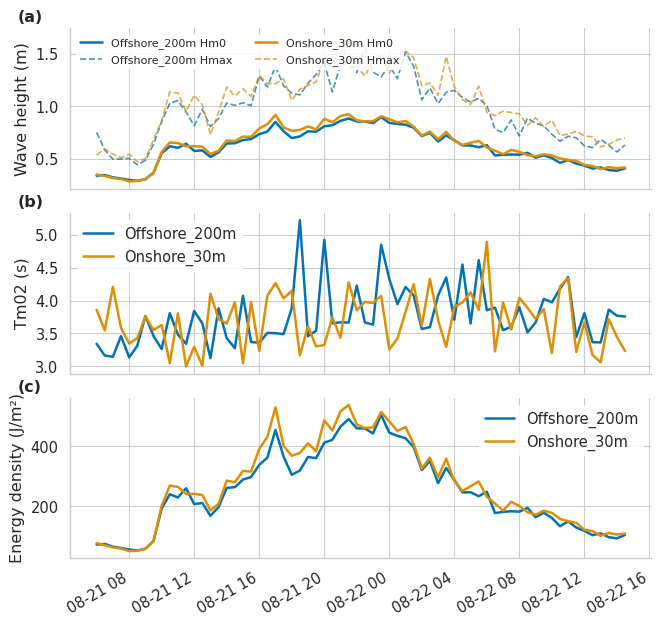

In [58]:
if len(all_results) > 1:
    fig, axes = plt.subplots(3, 1, figsize=(7.5, 7.8), sharex=True,
                              gridspec_kw={"hspace": 0.15})

    for name, results in all_results.items():
        axes[0].plot(results["burst_start"], results["Hm0_m"], color=SITE_COLORS[name], lw=1.8, ls="-", label=f"{name} Hm0")
        axes[0].plot(results["burst_start"], results["Hmax_m"], color=SITE_COLORS[name], lw=1.2, ls="--", alpha=0.75, label=f"{name} Hmax")
        axes[1].plot(results["burst_start"], results["Tm02_s"], color=SITE_COLORS[name], lw=1.8, label=name)
        axes[2].plot(results["burst_start"], results["wave_energy_Jm2"], color=SITE_COLORS[name], lw=1.8, label=name)

    axes[0].set_ylabel("Wave height (m)")
    axes[0].legend(loc="best", framealpha=0.85, edgecolor="none", ncol=2, fontsize=8)
    axes[0].text(-0.09, 1.04, "(a)", transform=axes[0].transAxes, fontweight="bold")
    sns.despine(ax=axes[0])

    axes[1].set_ylabel("Tm02 (s)")
    axes[1].legend(loc="best", framealpha=0.85, edgecolor="none")
    axes[1].text(-0.09, 1.04, "(b)", transform=axes[1].transAxes, fontweight="bold")
    sns.despine(ax=axes[1])

    axes[2].set_ylabel("Energy density (J/m²)")
    axes[2].legend(loc="best", framealpha=0.85, edgecolor="none")
    axes[2].text(-0.09, 1.04, "(c)", transform=axes[2].transAxes, fontweight="bold")
    sns.despine(ax=axes[2])

    for a in axes[:-1]:
        a.tick_params(labelbottom=False)
    fig.autofmt_xdate()
    fig.savefig(os.path.join(COMPARISON_DIR, "wave_conditions.png"), dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("Only one site configured - nothing to compare.")


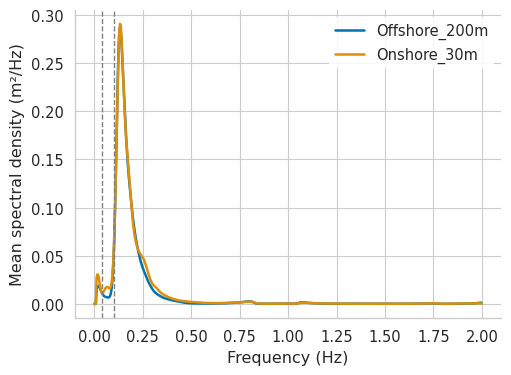

In [59]:
if len(all_results) > 1:
    fig, ax = plt.subplots(figsize=(5.5, 4))
    for name, spec in spectra.items():
        ax.plot(spec["f"], spec["Syy_mean"], color=SITE_COLORS[name], lw=1.8, label=name)
    for edge in (IG_MAX_HZ, SWELL_MAX_HZ):
        ax.axvline(edge, color="0.5", lw=1, ls="--")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Mean spectral density (m²/Hz)")
    ax.legend(loc="best", framealpha=0.85, edgecolor="none")
    sns.despine(ax=ax)
    fig.savefig(os.path.join(COMPARISON_DIR, "spectra.png"), dpi=200, bbox_inches="tight")
    plt.show()


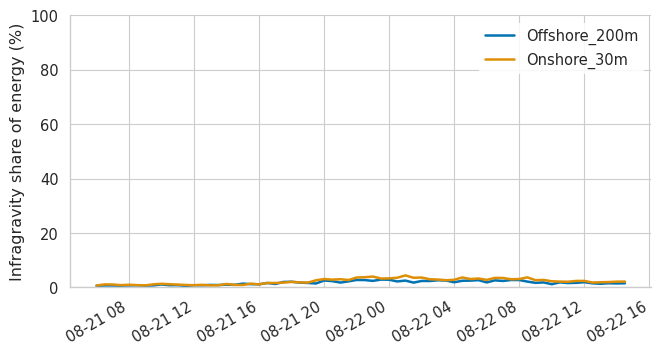

In [60]:
if len(all_results) > 1:
    fig, ax = plt.subplots(figsize=(7.5, 4))
    for name, results in all_results.items():
        ax.plot(results["burst_start"], results["ig_fraction_pct"], color=SITE_COLORS[name], lw=1.8, label=name)
    ax.set_ylabel("Infragravity share of energy (%)")
    ax.set_ylim(0, 100)
    ax.legend(loc="best", framealpha=0.85, edgecolor="none")
    sns.despine(ax=ax)
    fig.autofmt_xdate()
    fig.savefig(os.path.join(COMPARISON_DIR, "ig_fraction.png"), dpi=200, bbox_inches="tight")
    plt.show()


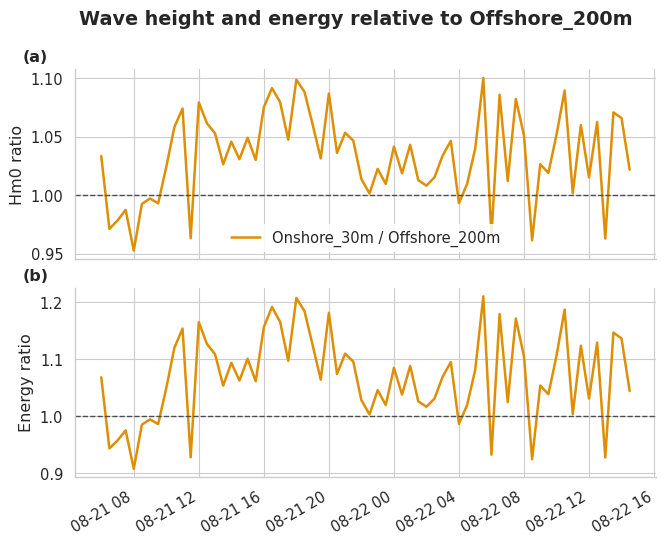


Onshore_30m / Offshore_200m: mean Hm0 ratio = 1.033, mean energy ratio = 1.069 (66 matched bursts)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [61]:
if len(all_results) > 1:
    ref = all_results[REFERENCE_SITE][["burst_start", "Hm0_m", "wave_energy_Jm2"]].rename(
        columns={"Hm0_m": "Hm0_ref", "wave_energy_Jm2": "E_ref"}
    )

    ratio_tables = {}
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.5, 6), sharex=True,
                                    gridspec_kw={"hspace": 0.15})
    for name, results in all_results.items():
        if name == REFERENCE_SITE:
            continue
        merged = results[["burst_start", "Hm0_m", "wave_energy_Jm2"]].merge(ref, on="burst_start", how="inner")
        merged["Hm0_ratio"] = merged["Hm0_m"] / merged["Hm0_ref"]
        merged["energy_ratio"] = merged["wave_energy_Jm2"] / merged["E_ref"]
        ratio_tables[name] = merged

        ax1.plot(merged["burst_start"], merged["Hm0_ratio"], color=SITE_COLORS[name], lw=1.8,
                  label=f"{name} / {REFERENCE_SITE}")
        ax2.plot(merged["burst_start"], merged["energy_ratio"], color=SITE_COLORS[name], lw=1.8,
                  label=f"{name} / {REFERENCE_SITE}")

    ax1.axhline(1.0, color="0.3", lw=1, ls="--")
    ax1.set_ylabel("Hm0 ratio")
    ax1.legend(loc="best", framealpha=0.85, edgecolor="none")
    ax1.text(-0.09, 1.04, "(a)", transform=ax1.transAxes, fontweight="bold")
    sns.despine(ax=ax1)

    ax2.axhline(1.0, color="0.3", lw=1, ls="--")
    ax2.set_ylabel("Energy ratio")
    ax2.text(-0.09, 1.04, "(b)", transform=ax2.transAxes, fontweight="bold")
    sns.despine(ax=ax2)

    ax1.tick_params(labelbottom=False)
    fig.autofmt_xdate()
    fig.suptitle(f"Wave height and energy relative to {REFERENCE_SITE}", fontweight="bold")
    fig.savefig(os.path.join(COMPARISON_DIR, "relative_wave_height_energy.png"), dpi=200, bbox_inches="tight")
    plt.show()

    for name, merged in ratio_tables.items():
        hm0_ratio_mean = merged["Hm0_ratio"].mean()
        energy_ratio_mean = merged["energy_ratio"].mean()
        print(f"\n{name} / {REFERENCE_SITE}: "
              f"mean Hm0 ratio = {hm0_ratio_mean:.3f}, "
              f"mean energy ratio = {energy_ratio_mean:.3f} "
              f"({len(merged)} matched bursts)")


## Next steps

- `ocn_objects["<name>"]` holds the full OCEANLYZ object if you want to dig
  further (e.g. `ocn.wave["Eta"]` for the reconstructed sea-surface
  elevation time series of any burst).
- Per-site outputs, in that site's own folder: `oceanlyz_results.csv` (one
  row per burst - depth, Hm0, Hmax, Tp, Tm01, Tm02, fp, total energy
  density, and the infragravity/swell/sea Hm0-equivalents, energies, and
  `ig_fraction_pct`), `wave_heights.csv` (one row per individual wave -
  time and height), and the four figures from section 6.
- Cross-site outputs, in `comparison_<site1>_<site2>_...`:
  `wave_conditions.png`, `spectra.png`, `ig_fraction.png`,
  `relative_wave_height_energy.png`.
- To change the burst length, edit `BURST_DURATION_S` and rerun from
  section 4. To change the infragravity/swell/sea band edges, edit
  `IG_MAX_HZ`/`SWELL_MAX_HZ` and rerun from section 4 (they're used inside
  `run_oceanlyz_site()`). To change which site the last comparison is
  measured against, edit `REFERENCE_SITE` and rerun from section 7.